# K-Means — Task 2

Code: `../scripts/kmeans.py`.

In [1]:
from pathlib import Path
from itertools import combinations
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
from scipy.stats import chi2_contingency

BASE = Path.cwd()
if (BASE / "A4").is_dir():
    BASE = BASE / "A4"
elif BASE.name == "notebooks":
    BASE = BASE.parent
sys.path.insert(0, str(BASE / "scripts"))
from kmeans import kmeans_plus_plus, kmeans_once, kmeans

customers = pd.read_csv(BASE / "powerbi/61_marketing_cleaned.csv")
customers.columns = customers.columns.str.extract(r"\[([^\]]+)\]$", expand=False)
pd.options.display.float_format = "{:.6g}".format

## Data

The six features cover age, income, spending and customer activity. Total Purchases and product amounts overlap with spending, so they are left out. ID, Education, Complain and campaign outcomes are excluded.

Three missing ages are filled with 44; eight incomes are capped at 118,350.5 in a copy. Scaling stops income dominating distances. One-hot encoding would add category-based distances and could overweight rare categories.

In [2]:
features = ["Age", "Income", "Total_Spending", "Recency",
            "Total_Children", "Customer_Tenure_Days"]
values = customers[features].copy()
values["Age"] = values["Age"].fillna(values["Age"].median())
values["Income"] = values["Income"].clip(upper=118350.5)
X = StandardScaler().fit_transform(values)
assert np.isfinite(X).all()
print(X.shape)

(2240, 6)


In [3]:
print("Running k-means clustering with k=3...")

Running k-means clustering with k=3...


## sklearn comparison

Both implementations start from the same centers. This avoids differences from sklearn's greedy k-means++ initializer.

In [3]:
checks = []
for k in range(2, 11):
    initial = kmeans_plus_plus(X, k, np.random.default_rng(42))
    _, labels, inertia, iterations = kmeans_once(X, initial, tol=0)
    reference = KMeans(n_clusters=k, init=initial.copy(), n_init=1,
                       max_iter=300, tol=0, algorithm="lloyd").fit(X)
    ari = adjusted_rand_score(labels, reference.labels_)
    checks.append([k, inertia, reference.inertia_, abs(inertia - reference.inertia_), ari])
    assert iterations < 300 and np.isclose(inertia, reference.inertia_, rtol=1e-9)
    assert ari > 0.999999
comparison = pd.DataFrame(checks, columns=["k", "Our inertia", "sklearn inertia", "Difference", "ARI"])
display(comparison)

,k,Our inertia,sklearn inertia,Difference,ARI
0,2,9775.27,9775.27,1.81899e-11,1
1,3,8703.38,8703.38,1.27329e-11,1
2,4,8001.55,8001.55,7.27596e-12,1
3,5,7187.2,7187.2,1.72804e-11,1
4,6,6658.9,6658.9,2.00089e-11,1
5,7,6232.13,6232.13,9.09495e-13,1
6,8,5834.18,5834.18,2.72848e-12,1
7,9,5541.7,5541.7,3.63798e-12,1
8,10,5302.57,5302.57,9.09495e-13,1


## Choosing k

Five seeds per k, with ten restarts each. Silhouette uses the lowest-inertia result; stability compares the five labelings using ARI.

In [4]:
rows = []
solutions = {}
for k in range(2, 11):
    labelings = []
    best_inertia = np.inf
    for seed in range(5):
        _, labels, inertia, iterations = kmeans(X, k, n_init=10, tol=1e-6, seed=seed)
        assert iterations < 300
        labelings.append(labels)
        if inertia < best_inertia:
            best_inertia = inertia
            best_labels = labels
            best_seed = seed

    solutions[k] = best_labels
    stability = [adjusted_rand_score(a, b) for a, b in combinations(labelings, 2)]
    rows.append({"k": k, "inertia": best_inertia,
                 "silhouette": silhouette_score(X, best_labels),
                 "stability_mean": np.mean(stability), "stability_min": min(stability),
                 "best_seed": best_seed})

scores = pd.DataFrame(rows)
scores.to_csv(BASE / "results/kmeans_scores.csv", index=False)
display(scores.round(4))

,k,inertia,silhouette,stability_mean,stability_min,best_seed
0,2,9775.07,0.2529,1,1,0
1,3,8586.71,0.1922,0.9995,0.9986,0
2,4,7835.2,0.1806,0.6276,0.4065,3
3,5,7187.02,0.1634,0.8154,0.5988,2
4,6,6645.49,0.1739,0.7093,0.3966,1
5,7,6179.56,0.1778,0.8856,0.773,3
6,8,5832.35,0.1775,0.7137,0.5829,1
7,9,5537.86,0.1768,0.5415,0.4199,3
8,10,5277.01,0.1794,0.5787,0.4564,0


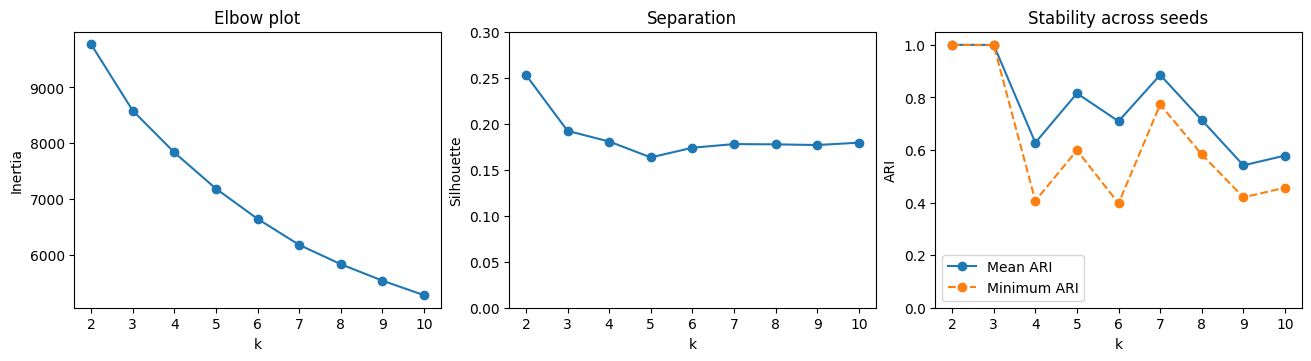

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5), layout="constrained")
axes[0].plot(scores.k, scores.inertia, "o-")
axes[0].set(title="Elbow plot", ylabel="Inertia")
axes[1].plot(scores.k, scores.silhouette, "o-")
axes[1].set(title="Separation", ylabel="Silhouette", ylim=(0, .3))
axes[2].plot(scores.k, scores.stability_mean, "o-", label="Mean ARI")
axes[2].plot(scores.k, scores.stability_min, "o--", label="Minimum ARI")
axes[2].set(title="Stability across seeds", ylabel="ARI", ylim=(0, 1.05))
axes[2].legend()
for ax in axes:
    ax.set(xlabel="k", xticks=range(2, 11))
plt.show()

k=2 has the best silhouette (0.253) and identical results across seeds. There is no clear elbow. Two groups are simple enough for offer testing, but the low silhouette suggests overlap.

In [6]:
labels = solutions[2]
uncapped = values.copy()
uncapped["Income"] = customers["Income"]
_, uncapped_labels, _, _ = kmeans(StandardScaler().fit_transform(uncapped), 2,
                                  n_init=10, tol=1e-6, seed=0)
print("ARI without income cap:", round(adjusted_rand_score(labels, uncapped_labels), 3))

ARI without income cap: 0.94


Without the income cap, ARI is 0.940, so most grouping remains similar.

## Profiles

These use original values, including uncapped income. Missing ages are omitted from averages.

In [7]:
profile_data = customers.assign(cluster=labels)
groups = profile_data.groupby("cluster")
display(groups.size().rename("Customers"))
display(groups[features + ["Total_Purchases"]].mean().round(2).T)
display(groups[["Income", "Total_Spending"]].median().round(2).T)

membership = profile_data[["ID", "cluster"]]
assert membership.ID.equals(customers.ID) and membership.ID.is_unique
membership.to_csv(BASE / "results/customer_clusters.csv", index=False)

cluster
0    1344
1     896
Name: Customers, dtype: int64

cluster,0,1
Age,43.5,47.5
Income,38442.3,72931.5
Total_Spending,189.24,1230.63
Recency,48.67,49.77
Total_Children,1.27,0.48
Customer_Tenure_Days,338.62,376.02
Total_Purchases,7.94,19.43


cluster,0,1
Income,38385.5,71493.5
Total_Spending,91.5,1173.5


**Cluster 0 — lower spending, more children:** 1,344 customers; mean spending 189 MU and 1.27 children. A group for testing value offers.

**Cluster 1 — higher spending, fewer children:** 896 customers; mean spending 1,231 MU and 0.48 children. A group for testing premium offers.

Recency is nearly equal, so neither group is noticeably more recent in its purchases.

## Education and complaints

In [8]:
tests = []
for attribute in ["Education", "Complain"]:
    table = pd.crosstab(profile_data.cluster, profile_data[attribute])
    chi2, p_value, dof, expected = chi2_contingency(table, correction=False)
    n = table.to_numpy().sum()
    smaller_dimension = min(table.shape[0] - 1, table.shape[1] - 1)
    v = np.sqrt(chi2 / (n * smaller_dimension))
    tests.append([attribute, chi2, dof, p_value, v, expected.min(), (expected < 5).sum()])
    print(attribute)
    display(table)
tests = pd.DataFrame(tests, columns=["Attribute", "Chi-square", "df", "p-value", "Cramer's V",
                                    "Minimum expected", "Expected cells < 5"])
display(tests)

Education


Education,2n Cycle,Basic,Graduation,Master,PhD
cluster,,,,,
0,132,54,662,231,265
1,71,0,465,139,221


Complain


Complain,0,1
cluster,,
0,1330,14
1,889,7


,Attribute,Chi-square,df,p-value,Cramer's V,Minimum expected,Expected cells < 5
0,Education,45.8593,4,2.6346e-09,0.143084,21.6,0
1,Complain,0.392569,1,0.530952,0.0132384,8.4,0


Education has a modest association with clusters (V=0.143, p=2.63e-9). Complaints show no clear difference (V=0.013, p=0.531). All expected counts exceed five, though there are only 21 complaints.

Testing the clustering inputs would be circular: their differences were used to create the groups.

References: [k-means++](https://research.google/pubs/k-means-the-advantages-of-careful-seeding/), [sklearn](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.KMeans.html), [silhouette](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.silhouette_score.html), [ARI](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.adjusted_rand_score.html), [chi-square](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.chi2_contingency.html).